# PRCP-1016 — Heart Disease Prediction

## 1. Problem Statement

The objective of this project is to analyze heart disease-related patient data
and develop machine learning models to predict the possibility of heart disease.

The project includes:

- Data analysis and exploratory data analysis (EDA)
- Data cleaning and preprocessing
- Feature engineering and selection
- Building multiple machine learning models
- Comparing model performance
- Selecting a suitable model for production
- Identifying challenges and the techniques used to overcome them
- Providing suggestions to hospitals for early identification of high-risk patients

> **Note:** This machine learning model is intended for educational and
> decision-support purposes only. It should not be used as a replacement
> for professional medical diagnosis.

In [1]:
# Import required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("Libraries imported successfully!")

Libraries imported successfully!


# 2. Load the Dataset

In this step, we load the heart disease dataset into a Pandas DataFrame.

A DataFrame is a table-like structure provided by Pandas that allows us
to analyze and manipulate the dataset easily.

In [5]:
# Load the datasets

values = pd.read_csv("values.csv")
labels = pd.read_csv("labels.csv")

print("Values dataset:")
print(values.head())

Values dataset:
  patient_id  slope_of_peak_exercise_st_segment               thal  \
0     0z64un                                  1             normal   
1     ryoo3j                                  2             normal   
2     yt1s1x                                  1             normal   
3     l2xjde                                  1  reversible_defect   
4     oyt4ek                                  3  reversible_defect   

   resting_blood_pressure  chest_pain_type  num_major_vessels  \
0                     128                2                  0   
1                     110                3                  0   
2                     125                4                  3   
3                     152                4                  0   
4                     178                1                  0   

   fasting_blood_sugar_gt_120_mg_per_dl  resting_ekg_results  \
0                                     0                    2   
1                                     0     

In [6]:
print("\nLabels dataset:")
print(labels.head())


Labels dataset:
  patient_id  heart_disease_present
0     0z64un                      0
1     ryoo3j                      0
2     yt1s1x                      1
3     l2xjde                      1
4     oyt4ek                      0


# 3. Understanding the Dataset

The dataset is divided into two files:

- **values.csv** contains the patient information and medical features.
- **labels.csv** contains the target variable, `heart_disease_present`.

The `patient_id` column is a unique identifier for each patient.
It does not contain useful medical information, so it will not be used
as a machine learning feature.

The target variable is:

- `0` → Heart disease not present
- `1` → Heart disease present

In [7]:
# Merge the values and labels datasets using patient_id

df = pd.merge(values, labels, on="patient_id", how="inner")

print("Dataset shape:", df.shape)

print("\nFirst 5 rows:")
display(df.head())

Dataset shape: (180, 15)

First 5 rows:


,patient_id,slope_of_peak_exercise_st_segment,thal,resting_blood_pressure,chest_pain_type,num_major_vessels,fasting_blood_sugar_gt_120_mg_per_dl,resting_ekg_results,serum_cholesterol_mg_per_dl,oldpeak_eq_st_depression,sex,age,max_heart_rate_achieved,exercise_induced_angina,heart_disease_present
0,0z64un,1,normal,128,2,0,0,2,308,0.0,1,45,170,0,0
1,ryoo3j,2,normal,110,3,0,0,0,214,1.6,0,54,158,0,0
2,yt1s1x,1,normal,125,4,3,0,2,304,0.0,1,77,162,1,1
3,l2xjde,1,reversible_defect,152,4,0,0,0,223,0.0,1,40,181,0,1
4,oyt4ek,3,reversible_defect,178,1,0,0,2,270,4.2,1,59,145,0,0


# 4. Dataset Information

In this step, we examine the structure of the dataset.

We will check:

- Number of rows and columns
- Column names
- Data types
- Non-null values
- Memory usage

This helps us understand the dataset before performing data cleaning
and preprocessing.

In [8]:
# Display dataset information

print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Dataset Shape: (180, 15)

Column Names:
['patient_id', 'slope_of_peak_exercise_st_segment', 'thal', 'resting_blood_pressure', 'chest_pain_type', 'num_major_vessels', 'fasting_blood_sugar_gt_120_mg_per_dl', 'resting_ekg_results', 'serum_cholesterol_mg_per_dl', 'oldpeak_eq_st_depression', 'sex', 'age', 'max_heart_rate_achieved', 'exercise_induced_angina', 'heart_disease_present']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180 entries, 0 to 179
Data columns (total 15 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   patient_id                            180 non-null    object 
 1   slope_of_peak_exercise_st_segment     180 non-null    int64  
 2   thal                                  180 non-null    object 
 3   resting_blood_pressure                180 non-null    int64  
 4   chest_pain_type                       180 non-null    int64  
 5   num_major_vessels 

# 5. Data Quality Check

Before performing exploratory data analysis, we check the dataset for:

1. Missing values
2. Duplicate records

Missing values can affect model training and may require imputation.

Duplicate records can cause the same patient information to appear more
than once and may affect the analysis and model evaluation.

In [9]:
# Check missing values

print("Missing values in each column:")
print(df.isnull().sum())

print("\nTotal missing values:")
print(df.isnull().sum().sum())

# Check duplicate rows

print("\nNumber of duplicate rows:")
print(df.duplicated().sum())

Missing values in each column:
patient_id                              0
slope_of_peak_exercise_st_segment       0
thal                                    0
resting_blood_pressure                  0
chest_pain_type                         0
num_major_vessels                       0
fasting_blood_sugar_gt_120_mg_per_dl    0
resting_ekg_results                     0
serum_cholesterol_mg_per_dl             0
oldpeak_eq_st_depression                0
sex                                     0
age                                     0
max_heart_rate_achieved                 0
exercise_induced_angina                 0
heart_disease_present                   0
dtype: int64

Total missing values:
0

Number of duplicate rows:
0


# 6. Statistical Summary

In this step, we calculate statistical summaries for the numerical
features in the dataset.

The summary includes:

- Count
- Mean
- Standard deviation
- Minimum value
- 25th percentile
- Median
- 75th percentile
- Maximum value

This helps us understand the distribution and range of the numerical
variables.

In [10]:
# Statistical summary of numerical columns

df.describe()

,slope_of_peak_exercise_st_segment,resting_blood_pressure,chest_pain_type,num_major_vessels,fasting_blood_sugar_gt_120_mg_per_dl,resting_ekg_results,serum_cholesterol_mg_per_dl,oldpeak_eq_st_depression,sex,age,max_heart_rate_achieved,exercise_induced_angina,heart_disease_present
count,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000
mean,1.550000,131.311111,3.155556,0.694444,0.161111,1.050000,249.211111,1.010000,0.688889,54.811111,149.483333,0.316667,0.444444
std,0.618838,17.010443,0.938454,0.969347,0.368659,0.998742,52.717969,1.121357,0.464239,9.334737,22.063513,0.466474,0.498290
min,1.000000,94.000000,1.000000,0.000000,0.000000,0.000000,126.000000,0.000000,0.000000,29.000000,96.000000,0.000000,0.000000
25%,1.000000,120.000000,3.000000,0.000000,0.000000,0.000000,213.750000,0.000000,0.000000,48.000000,132.000000,0.000000,0.000000
50%,1.000000,130.000000,3.000000,0.000000,0.000000,2.000000,245.500000,0.800000,1.000000,55.000000,152.000000,0.000000,0.000000
75%,2.000000,140.000000,4.000000,1.000000,0.000000,2.000000,281.250000,1.600000,1.000000,62.000000,166.250000,1.000000,1.000000
max,3.000000,180.000000,4.000000,3.000000,1.000000,2.000000,564.000000,6.200000,1.000000,77.000000,202.000000,1.000000,1.000000


# 7. Categorical Feature Analysis

The `thal` column is a categorical feature that represents the result
of a thallium stress test.

We will examine the unique categories and their frequency in the dataset.

Understanding categorical values is important because machine learning
models generally require categorical variables to be converted into
numerical form during preprocessing.

In [11]:
# Check unique values and their counts in the categorical column

print("Unique values in thal:")
print(df["thal"].unique())

print("\nFrequency of each thal category:")
print(df["thal"].value_counts())

Unique values in thal:
['normal' 'reversible_defect' 'fixed_defect']

Frequency of each thal category:
thal
normal               98
reversible_defect    74
fixed_defect          8
Name: count, dtype: int64


# 8. Target Variable Analysis

The target variable is `heart_disease_present`.

It indicates whether heart disease is present:

- `0` → Heart disease not present
- `1` → Heart disease present

We will check the number and percentage of patients in each class.

This helps us determine whether the target variable is balanced or imbalanced.

Heart Disease Distribution:
heart_disease_present
0    100
1     80
Name: count, dtype: int64

Percentage Distribution:
heart_disease_present
0    55.56
1    44.44
Name: count, dtype: float64


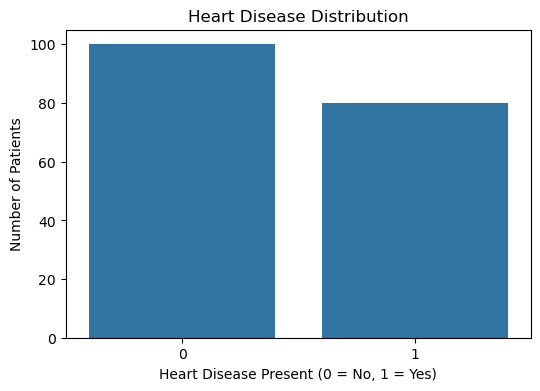

In [12]:
# Count the target classes

target_counts = df["heart_disease_present"].value_counts().sort_index()

print("Heart Disease Distribution:")
print(target_counts)

print("\nPercentage Distribution:")
print((target_counts / len(df) * 100).round(2))

# Visualize target distribution

plt.figure(figsize=(6, 4))

sns.countplot(
    data=df,
    x="heart_disease_present"
)

plt.title("Heart Disease Distribution")
plt.xlabel("Heart Disease Present (0 = No, 1 = Yes)")
plt.ylabel("Number of Patients")

plt.show()

# 9. Distribution of Numerical Features

In this step, we visualize the numerical features using histograms.

Histograms help us understand how the values are distributed and can
help identify skewness, unusual values, and possible outliers.

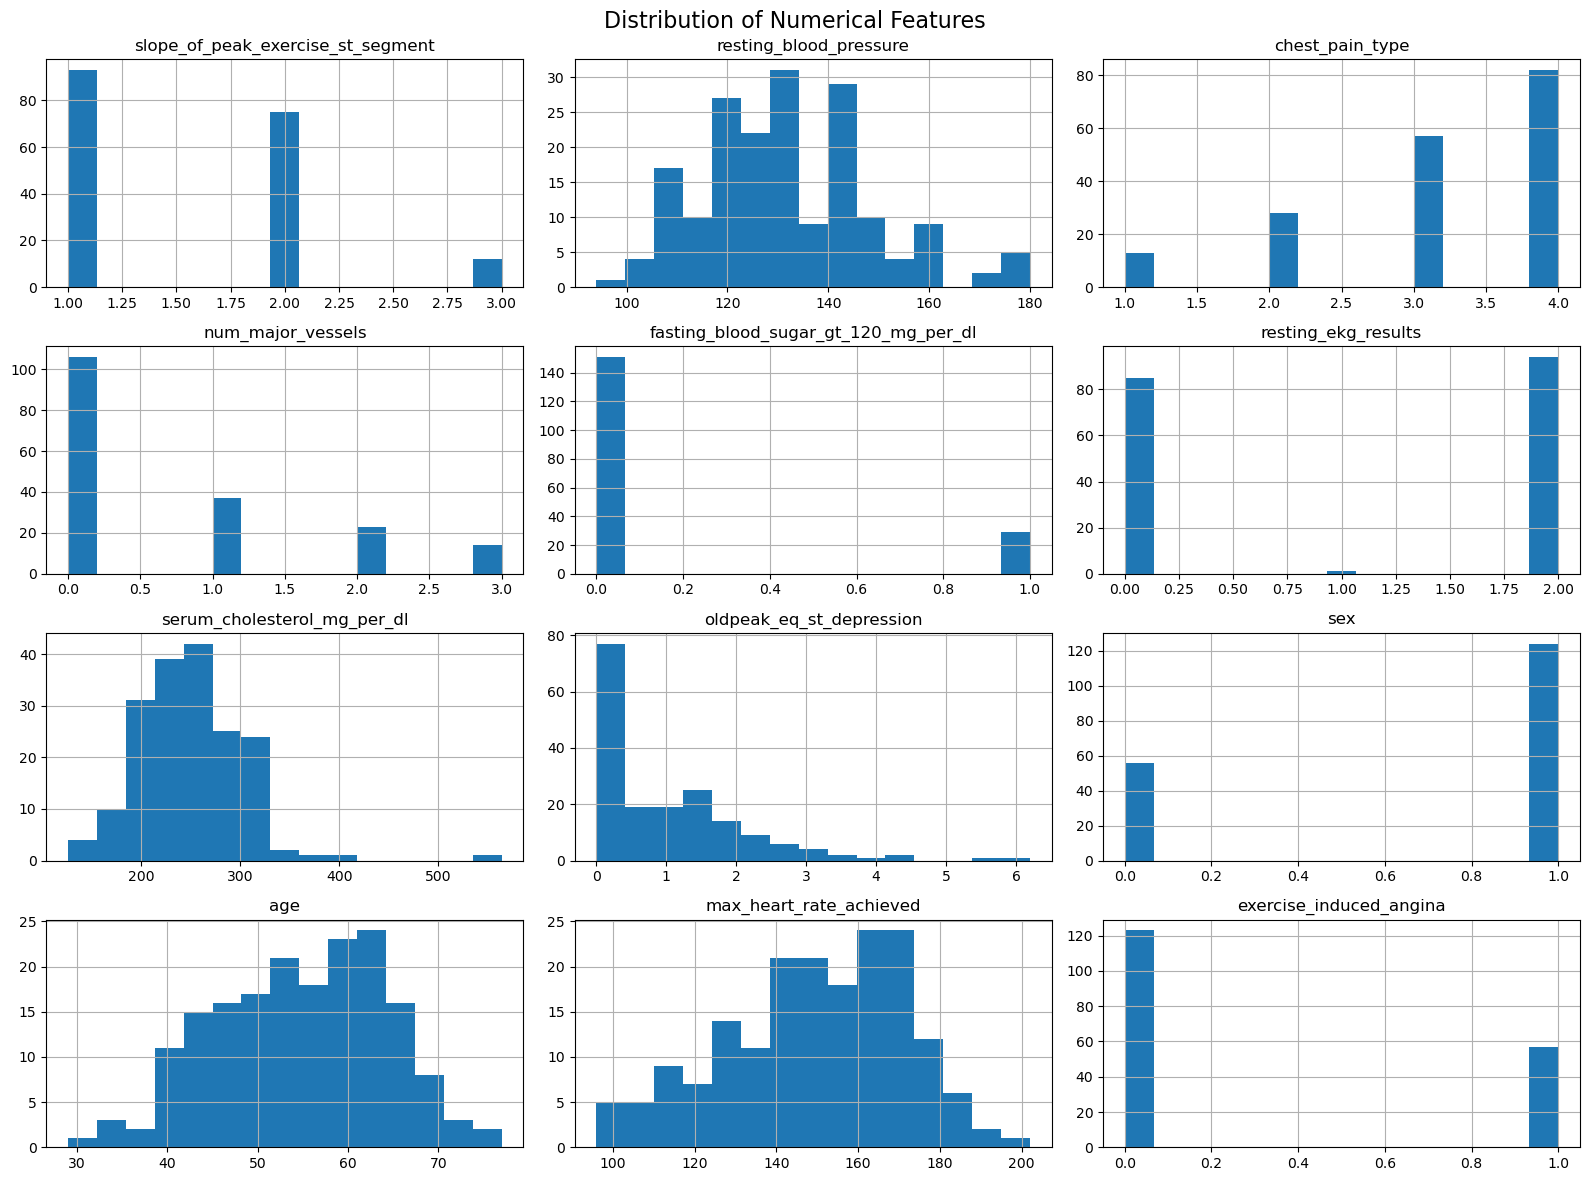

In [13]:
# Select numerical features

numerical_features = [
    "slope_of_peak_exercise_st_segment",
    "resting_blood_pressure",
    "chest_pain_type",
    "num_major_vessels",
    "fasting_blood_sugar_gt_120_mg_per_dl",
    "resting_ekg_results",
    "serum_cholesterol_mg_per_dl",
    "oldpeak_eq_st_depression",
    "sex",
    "age",
    "max_heart_rate_achieved",
    "exercise_induced_angina"
]

# Plot distributions

df[numerical_features].hist(
    figsize=(16, 12),
    bins=15
)

plt.suptitle("Distribution of Numerical Features", fontsize=16)
plt.tight_layout()
plt.show()

# 10. Correlation Analysis

Correlation analysis helps us understand the relationship between
numerical variables.

A correlation value ranges from -1 to +1:

- +1 → strong positive relationship
- 0 → little or no linear relationship
- -1 → strong negative relationship

We will create a correlation heatmap to visualize the relationships
between the numerical features and the target variable.

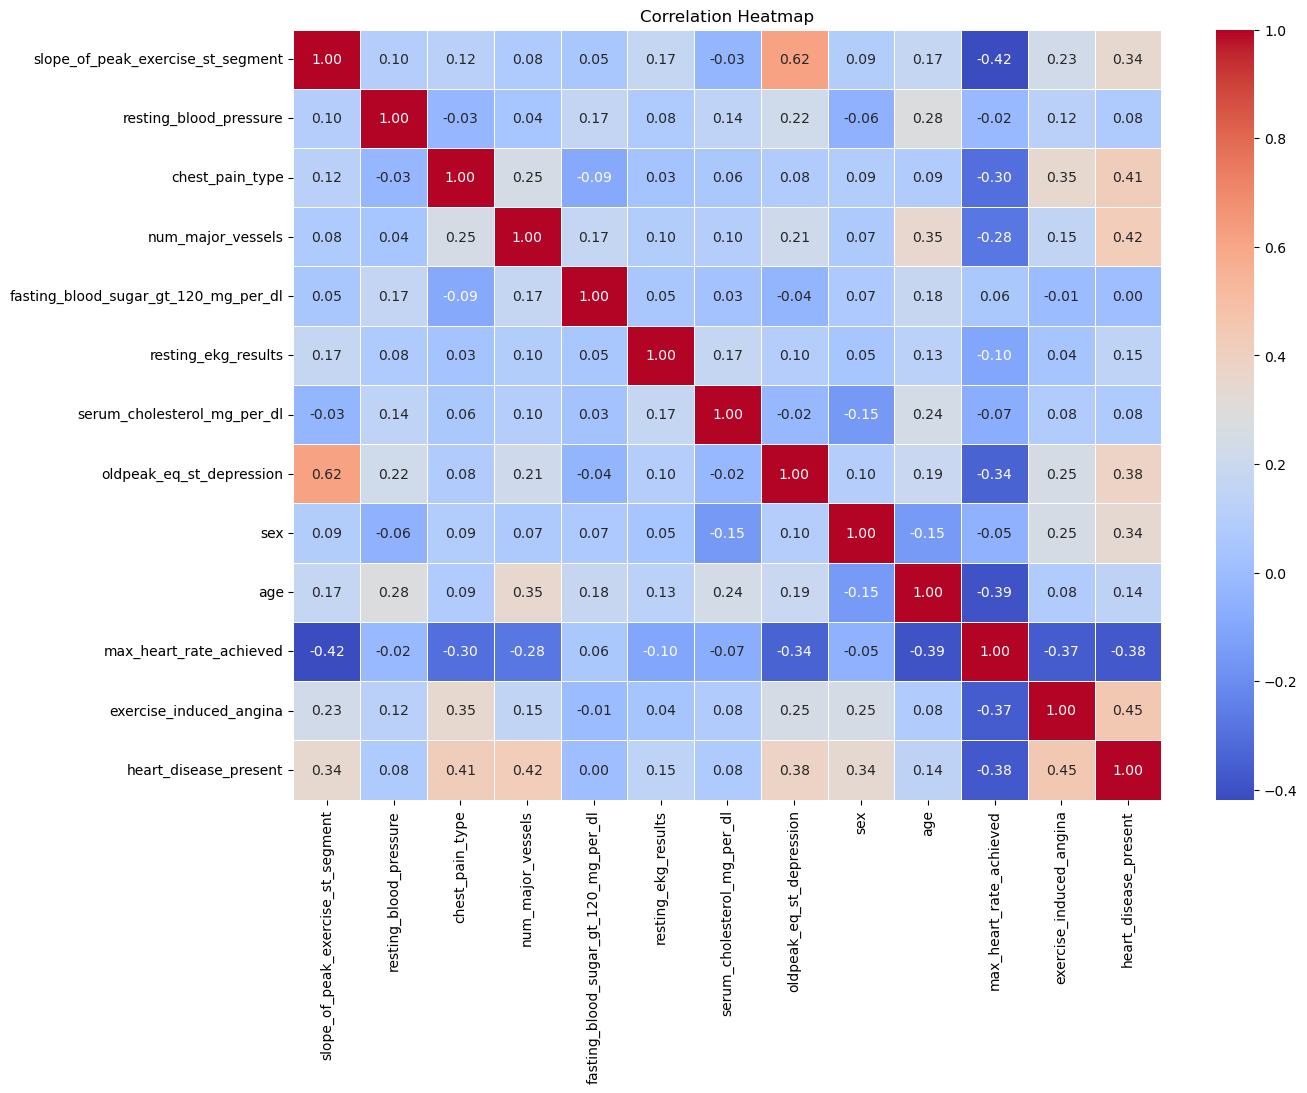

In [14]:
# Select numerical columns

correlation_data = df[numerical_features + ["heart_disease_present"]]

# Calculate correlation matrix

correlation_matrix = correlation_data.corr()

# Plot correlation heatmap

plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap")
plt.show()

## Outlier Detection

Outliers are unusually high or low values in a dataset.

For example:
- A very high cholesterol value
- An unusually high blood pressure value
- An unusually high `oldpeak` value

We will use **boxplots** to visually identify possible outliers.

### Why do we check outliers?

Outliers can sometimes:
- Affect statistical analysis
- Affect some machine learning models
- Indicate unusual observations or data-entry problems

However, we should **not automatically remove outliers**. First, we need to understand them.

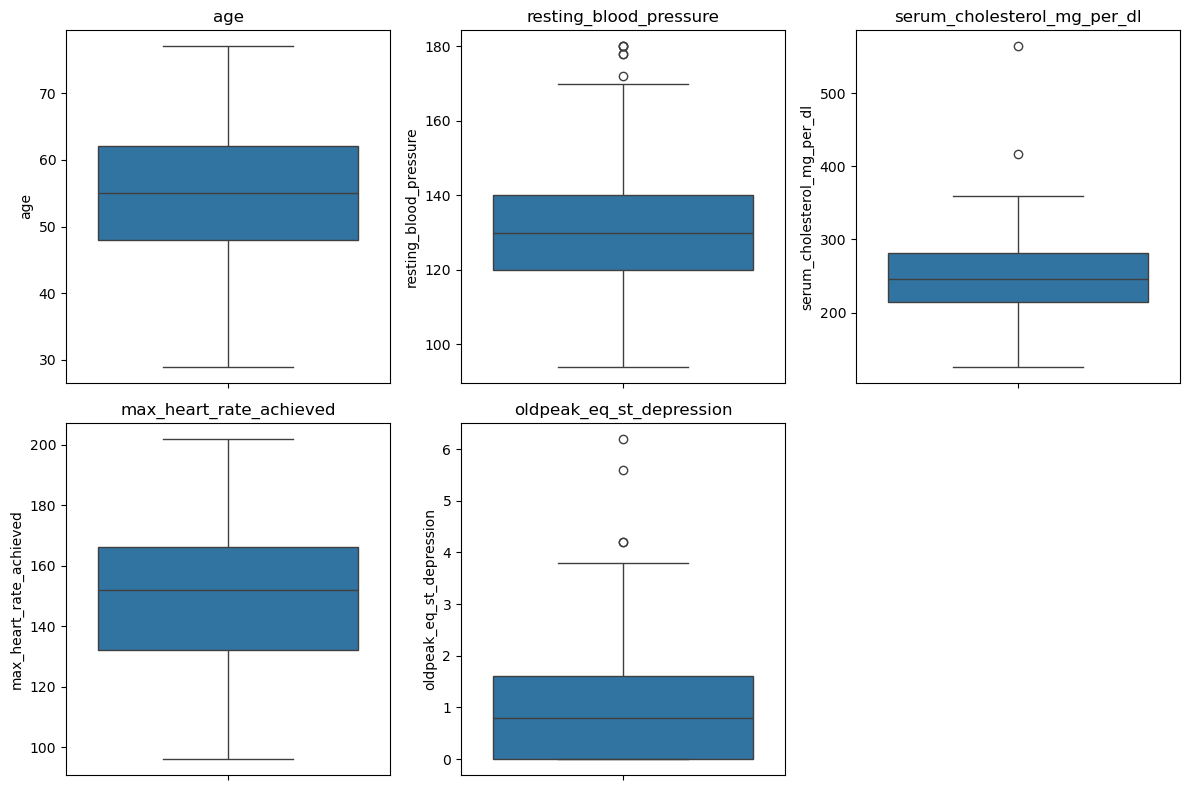

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select numerical features
numerical_features = [
    'age',
    'resting_blood_pressure',
    'serum_cholesterol_mg_per_dl',
    'max_heart_rate_achieved',
    'oldpeak_eq_st_depression'
]

# Create boxplots
plt.figure(figsize=(12, 8))

for i, feature in enumerate(numerical_features, 1):
    plt.subplot(2, 3, i)
    sns.boxplot(y=df[feature])
    plt.title(feature)

plt.tight_layout()
plt.show()

## Outlier Detection Using IQR

A boxplot shows possible outliers visually.

Now we will calculate the exact number of outliers using the **IQR (Interquartile Range)** method.

### IQR Formula

IQR = Q3 - Q1

Lower Bound = Q1 - 1.5 × IQR

Upper Bound = Q3 + 1.5 × IQR

Any value below the lower bound or above the upper bound is considered a potential outlier.

We will only identify the outliers at this stage.
We will NOT remove them automatically because an outlier may represent a genuine observation.

In [16]:
# Features for outlier detection
numerical_features = [
    'age',
    'resting_blood_pressure',
    'serum_cholesterol_mg_per_dl',
    'max_heart_rate_achieved',
    'oldpeak_eq_st_depression'
]

# Calculate and display outliers
for feature in numerical_features:
    
    Q1 = df[feature].quantile(0.25)
    Q3 = df[feature].quantile(0.75)
    
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    outliers = df[
        (df[feature] < lower_bound) |
        (df[feature] > upper_bound)
    ]
    
    print(f"{feature}")
    print(f"Q1: {Q1:.2f}")
    print(f"Q3: {Q3:.2f}")
    print(f"IQR: {IQR:.2f}")
    print(f"Lower Bound: {lower_bound:.2f}")
    print(f"Upper Bound: {upper_bound:.2f}")
    print(f"Number of outliers: {len(outliers)}")
    print("-" * 50)

age
Q1: 48.00
Q3: 62.00
IQR: 14.00
Lower Bound: 27.00
Upper Bound: 83.00
Number of outliers: 0
--------------------------------------------------
resting_blood_pressure
Q1: 120.00
Q3: 140.00
IQR: 20.00
Lower Bound: 90.00
Upper Bound: 170.00
Number of outliers: 6
--------------------------------------------------
serum_cholesterol_mg_per_dl
Q1: 213.75
Q3: 281.25
IQR: 67.50
Lower Bound: 112.50
Upper Bound: 382.50
Number of outliers: 2
--------------------------------------------------
max_heart_rate_achieved
Q1: 132.00
Q3: 166.25
IQR: 34.25
Lower Bound: 80.62
Upper Bound: 217.62
Number of outliers: 0
--------------------------------------------------
oldpeak_eq_st_depression
Q1: 0.00
Q3: 1.60
IQR: 1.60
Lower Bound: -2.40
Upper Bound: 4.00
Number of outliers: 4
--------------------------------------------------


## Outlier Treatment

The IQR method identified some potential outliers.

However, we will not remove them immediately because these values may represent genuine patient observations.

Before deciding how to handle them, we will inspect the actual outlier values.

This helps us determine whether they are:
- Valid observations
- Extreme but realistic values
- Possible data-entry errors

In [17]:
# Display the actual outlier values

for feature in numerical_features:
    
    Q1 = df[feature].quantile(0.25)
    Q3 = df[feature].quantile(0.75)
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    outliers = df[
        (df[feature] < lower_bound) |
        (df[feature] > upper_bound)
    ][feature]
    
    print(f"\n{feature}")
    print(outliers.values)


age
[]

resting_blood_pressure
[178 180 172 178 180 180]

serum_cholesterol_mg_per_dl
[417 564]

max_heart_rate_achieved
[]

oldpeak_eq_st_depression
[4.2 4.2 5.6 6.2]


## Outlier Treatment Decision

The identified outliers are:

- Resting blood pressure: 172–180
- Serum cholesterol: 417 and 564
- Oldpeak: 4.2, 4.2, 5.6, and 6.2

These values are extreme, but they can represent real patient measurements.

Therefore, we will **keep these observations** and not remove or modify them.

Removing valid medical observations could cause loss of useful information and may negatively affect the model.

We will let the machine learning model learn from the complete dataset.

In [19]:
# Check the dataset size before continuing

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

# Check for missing values
print("\nMissing values:")
print(df.isnull().sum())

Number of rows: 180
Number of columns: 15

Missing values:
patient_id                              0
slope_of_peak_exercise_st_segment       0
thal                                    0
resting_blood_pressure                  0
chest_pain_type                         0
num_major_vessels                       0
fasting_blood_sugar_gt_120_mg_per_dl    0
resting_ekg_results                     0
serum_cholesterol_mg_per_dl             0
oldpeak_eq_st_depression                0
sex                                     0
age                                     0
max_heart_rate_achieved                 0
exercise_induced_angina                 0
heart_disease_present                   0
dtype: int64


## Outlier Treatment

Outliers are values that are unusually high or low compared with the rest of the data.

From our IQR analysis:

- `age` → 0 outliers
- `resting_blood_pressure` → 6 outliers
- `serum_cholesterol_mg_per_dl` → 2 outliers
- `max_heart_rate_achieved` → 0 outliers
- `oldpeak_eq_st_depression` → 4 outliers

Because this dataset contains only 180 rows, removing outlier rows could result in losing useful information.

Therefore, we will use **IQR capping**.

IQR capping means:
- Values below the lower bound are replaced with the lower bound.
- Values above the upper bound are replaced with the upper bound.

This keeps all 180 rows while reducing the effect of extreme values.

In [20]:
# Columns where outliers were detected
outlier_columns = [
    'resting_blood_pressure',
    'serum_cholesterol_mg_per_dl',
    'oldpeak_eq_st_depression'
]

# Apply IQR capping
for column in outlier_columns:
    
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    df[column] = df[column].clip(
        lower=lower_bound,
        upper=upper_bound
    )

print("Outliers capped successfully.")

Outliers capped successfully.


## Categorical Feature Encoding

Machine learning models work with numerical data.

Our dataset contains categorical features such as:

- `thal`
- `chest_pain_type`
- `resting_ekg_results`
- `sex`
- `exercise_induced_angina`
- `slope_of_peak_exercise_st_segment`
- `fasting_blood_sugar_gt_120_mg_per_dl`

Some of these are already represented using numbers, but their numbers represent categories rather than actual quantities.

We will inspect the unique values of the categorical columns before deciding how to encode them.

In [21]:
categorical_columns = [
    'slope_of_peak_exercise_st_segment',
    'thal',
    'chest_pain_type',
    'resting_ekg_results',
    'sex',
    'exercise_induced_angina',
    'fasting_blood_sugar_gt_120_mg_per_dl'
]

for column in categorical_columns:
    print(column)
    print(df[column].unique())
    print()

slope_of_peak_exercise_st_segment
[1 2 3]

thal
['normal' 'reversible_defect' 'fixed_defect']

chest_pain_type
[2 3 4 1]

resting_ekg_results
[2 0 1]

sex
[1 0]

exercise_induced_angina
[0 1]

fasting_blood_sugar_gt_120_mg_per_dl
[0 1]



## Encoding Categorical Features

We have identified the categorical features and their unique values.

- `thal` contains text categories, so it needs **One-Hot Encoding**.
- `slope_of_peak_exercise_st_segment` has ordered categories (1, 2, 3), so we can keep it as numerical values.
- `chest_pain_type` is categorical, even though it uses numbers, so we will use **One-Hot Encoding**.
- `resting_ekg_results` is also categorical, so we will use **One-Hot Encoding**.
- `sex`, `exercise_induced_angina`, and `fasting_blood_sugar_gt_120_mg_per_dl` are binary features, so they can remain as 0 and 1.

We will encode the categorical features before training the machine learning models.

In [22]:
# One-hot encode categorical features

categorical_to_encode = [
    'thal',
    'chest_pain_type',
    'resting_ekg_results'
]

df = pd.get_dummies(
    df,
    columns=categorical_to_encode,
    drop_first=True,
    dtype=int
)

df.head()

,patient_id,slope_of_peak_exercise_st_segment,resting_blood_pressure,num_major_vessels,fasting_blood_sugar_gt_120_mg_per_dl,serum_cholesterol_mg_per_dl,oldpeak_eq_st_depression,sex,age,max_heart_rate_achieved,exercise_induced_angina,heart_disease_present,thal_normal,thal_reversible_defect,chest_pain_type_2,chest_pain_type_3,chest_pain_type_4,resting_ekg_results_1,resting_ekg_results_2
0,0z64un,1,128,0,0,308.0,0.0,1,45,170,0,0,1,0,1,0,0,0,1
1,ryoo3j,2,110,0,0,214.0,1.6,0,54,158,0,0,1,0,0,1,0,0,0
2,yt1s1x,1,125,3,0,304.0,0.0,1,77,162,1,1,1,0,0,0,1,0,1
3,l2xjde,1,152,0,0,223.0,0.0,1,40,181,0,1,0,1,0,0,1,0,0
4,oyt4ek,3,170,0,0,270.0,4.0,1,59,145,0,0,0,1,0,0,0,0,1


## Separating Features and Target

We need to separate the dataset into:

- **X (Features):** The input variables used by the machine learning model.
- **y (Target):** The value we want the model to predict.

Our target column is:

`heart_disease_present`

Therefore:

- X = all columns except `heart_disease_present`
- y = `heart_disease_present`

In [23]:
# Separate features and target

X = df.drop('heart_disease_present', axis=1)
y = df['heart_disease_present']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (180, 18)
Target shape: (180,)


## Train-Test Split

We split our dataset into two parts:

- **Training data (80%)** → Used to teach the model.
- **Testing data (20%)** → Used to check how well the model performs on unseen data.

We will use `random_state=42` so that we get the same split every time we run the code.

In [25]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (144, 18)
X_test: (36, 18)
y_train: (144,)
y_test: (36,)


## Feature Scaling

Our features have very different ranges.

For example:

- `age` → around 29–77
- `resting_blood_pressure` → around 94–180
- `serum_cholesterol_mg_per_dl` → around 126–564
- `max_heart_rate_achieved` → around 96–202

Features with larger numerical values can have a greater influence on some machine learning algorithms.

We will use **StandardScaler** to put the numerical features on a similar scale.

StandardScaler transforms a feature using:

z = (x - mean) / standard deviation

### Important

We will:

1. Fit the scaler only on `X_train`.
2. Transform `X_train`.
3. Transform `X_test` using the same scaler.

This prevents information from the test set from leaking into the training process.

In [27]:
# Remove patient ID because it is only an identifier

X = X.drop('patient_id', axis=1)

print("Features shape:", X.shape)

Features shape: (180, 17)


In [28]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (144, 17)
X_test: (36, 17)
y_train: (144,)
y_test: (36,)


In [29]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("X_train_scaled shape:", X_train_scaled.shape)
print("X_test_scaled shape:", X_test_scaled.shape)

X_train_scaled shape: (144, 17)
X_test_scaled shape: (36, 17)


## Training the First Model — Logistic Regression

Our target variable `heart_disease_present` has two possible values:

- `0` → No heart disease
- `1` → Heart disease

Therefore, this is a **binary classification problem**.

We will start with **Logistic Regression** as our baseline model.

Logistic Regression predicts the probability of belonging to class 0 or class 1.

We will train the model using the training data and then make predictions on the unseen test data.

In [ ]:
from sklearn.linear_model import LogisticRegression

# Create the model
logistic_model = LogisticRegression(random_state=42)

# Train the model
logistic_model.fit(X_train_scaled, y_train)

print("Logistic Regression model trained successfully.")

In [31]:
y_pred_logistic = logistic_model.predict(X_test_scaled)

print("Predictions:", y_pred_logistic)

Predictions: [0 1 1 0 0 1 0 0 1 1 0 1 1 1 0 0 0 1 1 1 1 1 1 1 0 0 0 0 1 0 1 1 1 0 0 1]


## Evaluating Logistic Regression

We will compare the model's predictions (`y_pred_logistic`) with the actual test values (`y_test`).

We will use four important classification metrics:

- **Accuracy** → Overall percentage of correct predictions.
- **Precision** → Of the patients predicted as having heart disease, how many actually have it?
- **Recall** → Of the patients who actually have heart disease, how many did the model identify?
- **F1-score** → A balance between precision and recall.

We will also use a **confusion matrix** to see the number of correct and incorrect predictions for each class.

In [32]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

accuracy = accuracy_score(y_test, y_pred_logistic)
precision = precision_score(y_test, y_pred_logistic)
recall = recall_score(y_test, y_pred_logistic)
f1 = f1_score(y_test, y_pred_logistic)

print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_logistic))

Accuracy : 0.8888888888888888
Precision: 0.8
Recall   : 1.0
F1 Score : 0.8888888888888888

Confusion Matrix:
[[16  4]
 [ 0 16]]


## Training the Second Model — Decision Tree

A Decision Tree makes predictions by asking a sequence of questions about the features.

For example:

- Is age greater than a certain value?
- Is the number of major vessels greater than 0?
- Is exercise-induced angina present?

The tree keeps splitting the data until it reaches a prediction.

We will train a Decision Tree using the same training data and evaluate it using the same test data.

In [33]:
from sklearn.tree import DecisionTreeClassifier

# Create the model
decision_tree_model = DecisionTreeClassifier(
    random_state=42
)

# Train the model
decision_tree_model.fit(X_train_scaled, y_train)

# Make predictions
y_pred_tree = decision_tree_model.predict(X_test_scaled)

print("Decision Tree predictions:")
print(y_pred_tree)

Decision Tree predictions:
[1 1 1 0 0 1 0 0 1 1 0 1 0 0 0 0 0 1 1 0 1 1 0 0 0 1 0 0 1 1 0 1 1 0 1 0]


In [34]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

accuracy_tree = accuracy_score(y_test, y_pred_tree)
precision_tree = precision_score(y_test, y_pred_tree)
recall_tree = recall_score(y_test, y_pred_tree)
f1_tree = f1_score(y_test, y_pred_tree)

print("Accuracy :", accuracy_tree)
print("Precision:", precision_tree)
print("Recall   :", recall_tree)
print("F1 Score :", f1_tree)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_tree))

Accuracy : 0.6944444444444444
Precision: 0.6470588235294118
Recall   : 0.6875
F1 Score : 0.6666666666666666

Confusion Matrix:
[[14  6]
 [ 5 11]]


## Training the Third Model — Random Forest

Random Forest is an ensemble machine learning algorithm.

Instead of using one Decision Tree, it creates multiple Decision Trees and combines their predictions.

This can make the model more robust and reduce the risk of overfitting compared with using a single Decision Tree.

We will train a Random Forest using our training data and test it on the same test data.

In [35]:
from sklearn.ensemble import RandomForestClassifier

# Create the model
random_forest_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train the model
random_forest_model.fit(X_train_scaled, y_train)

# Make predictions
y_pred_rf = random_forest_model.predict(X_test_scaled)

print("Random Forest predictions:")
print(y_pred_rf)

Random Forest predictions:
[0 1 1 0 0 1 1 0 1 1 0 1 0 1 0 0 0 1 0 1 1 1 1 1 0 0 0 0 1 1 1 1 1 0 0 1]


In [36]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf)
recall_rf = recall_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf)

print("Accuracy :", accuracy_rf)
print("Precision:", precision_rf)
print("Recall   :", recall_rf)
print("F1 Score :", f1_rf)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

Accuracy : 0.8888888888888888
Precision: 0.8
Recall   : 1.0
F1 Score : 0.8888888888888888

Confusion Matrix:
[[16  4]
 [ 0 16]]


## Training the Fourth Model — Support Vector Machine (SVM)

Support Vector Machine (SVM) is a classification algorithm that finds a boundary
that separates different classes.

In our project, the two classes are:

- `0` → No heart disease
- `1` → Heart disease

SVM works well with scaled features, which is why we performed feature scaling
before training the model.

In [37]:
from sklearn.svm import SVC

# Create the model
svm_model = SVC(random_state=42)

# Train the model
svm_model.fit(X_train_scaled, y_train)

# Make predictions
y_pred_svm = svm_model.predict(X_test_scaled)

print("SVM predictions:")
print(y_pred_svm)

SVM predictions:
[0 1 1 0 0 0 0 0 1 1 0 1 0 1 0 0 0 1 1 1 1 1 1 1 0 0 0 0 1 1 1 1 1 0 0 1]


In [38]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

accuracy_svm = accuracy_score(y_test, y_pred_svm)
precision_svm = precision_score(y_test, y_pred_svm)
recall_svm = recall_score(y_test, y_pred_svm)
f1_svm = f1_score(y_test, y_pred_svm)

print("Accuracy :", accuracy_svm)
print("Precision:", precision_svm)
print("Recall   :", recall_svm)
print("F1 Score :", f1_svm)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_svm))

Accuracy : 0.8611111111111112
Precision: 0.7894736842105263
Recall   : 0.9375
F1 Score : 0.8571428571428571

Confusion Matrix:
[[16  4]
 [ 1 15]]


## Training the Fifth Model — K-Nearest Neighbors (KNN)

K-Nearest Neighbors (KNN) predicts the class of a new patient by looking at
the most similar patients in the training data.

For example, if most of the nearest patients belong to class `1`,
KNN predicts class `1`.

KNN is sensitive to the scale of features, so we use our scaled data.

In [40]:
from sklearn.neighbors import KNeighborsClassifier

# Create the model
knn_model = KNeighborsClassifier(n_neighbors=5)

# Train the model
knn_model.fit(X_train_scaled, y_train)

# Make predictions
y_pred_knn = knn_model.predict(X_test_scaled)

print("KNN predictions:")
print(y_pred_knn)

KNN predictions:
[0 1 1 0 0 0 0 0 1 1 0 1 0 1 0 0 0 1 1 1 1 1 1 1 0 0 0 0 1 1 1 1 1 0 0 1]


In [41]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

accuracy_knn = accuracy_score(y_test, y_pred_knn)
precision_knn = precision_score(y_test, y_pred_knn)
recall_knn = recall_score(y_test, y_pred_knn)
f1_knn = f1_score(y_test, y_pred_knn)

print("Accuracy :", accuracy_knn)
print("Precision:", precision_knn)
print("Recall   :", recall_knn)
print("F1 Score :", f1_knn)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_knn))

Accuracy : 0.8611111111111112
Precision: 0.7894736842105263
Recall   : 0.9375
F1 Score : 0.8571428571428571

Confusion Matrix:
[[16  4]
 [ 1 15]]


## Model Performance Comparison

We have trained and evaluated five classification models:

1. Logistic Regression
2. Decision Tree
3. Random Forest
4. Support Vector Machine (SVM)
5. K-Nearest Neighbors (KNN)

We will compare their Accuracy, Precision, Recall, and F1 Score.

In [42]:
import pandas as pd

model_results = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Decision Tree',
        'Random Forest',
        'SVM',
        'KNN'
    ],
    'Accuracy': [
        accuracy,
        accuracy_tree,
        accuracy_rf,
        accuracy_svm,
        accuracy_knn
    ],
    'Precision': [
        precision,
        precision_tree,
        precision_rf,
        precision_svm,
        precision_knn
    ],
    'Recall': [
        recall,
        recall_tree,
        recall_rf,
        recall_svm,
        recall_knn
    ],
    'F1 Score': [
        f1,
        f1_tree,
        f1_rf,
        f1_svm,
        f1_knn
    ]
})

model_results

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.888889,0.800000,1.0000,0.888889
1,Decision Tree,0.694444,0.647059,0.6875,0.666667
2,Random Forest,0.888889,0.800000,1.0000,0.888889
3,SVM,0.861111,0.789474,0.9375,0.857143
4,KNN,0.861111,0.789474,0.9375,0.857143


## Hyperparameter Tuning — Logistic Regression

A machine learning model has **hyperparameters** that control how the model
learns.

For Logistic Regression, one important hyperparameter is `C`.

`C` controls the strength of regularization:

- Smaller `C` → stronger regularization
- Larger `C` → weaker regularization

Instead of choosing one value manually, we will test several values and use
cross-validation to find a suitable setting.

We will use `GridSearchCV` to search through different `C` values.

In [43]:
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression

logistic_params = {
    'C': [0.01, 0.1, 1, 10, 100]
}

logistic_grid = GridSearchCV(
    LogisticRegression(random_state=42),
    logistic_params,
    cv=5,
    scoring='f1'
)

logistic_grid.fit(X_train_scaled, y_train)

print("Best parameters:", logistic_grid.best_params_)
print("Best cross-validation F1 score:", logistic_grid.best_score_)

Best parameters: {'C': 0.01}
Best cross-validation F1 score: 0.7974987974987975


## Evaluating the Tuned Logistic Regression

The best hyperparameter found during cross-validation was:

`C = 0.01`

We will now use the tuned model to make predictions on the test data.

The test data is still kept separate from the hyperparameter search.

In [44]:
# Get the best Logistic Regression model

best_logistic_model = logistic_grid.best_estimator_

# Make predictions on test data
y_pred_logistic_tuned = best_logistic_model.predict(X_test_scaled)

# Evaluate the tuned model
accuracy_logistic_tuned = accuracy_score(
    y_test, y_pred_logistic_tuned
)

precision_logistic_tuned = precision_score(
    y_test, y_pred_logistic_tuned
)

recall_logistic_tuned = recall_score(
    y_test, y_pred_logistic_tuned
)

f1_logistic_tuned = f1_score(
    y_test, y_pred_logistic_tuned
)

print("Accuracy :", accuracy_logistic_tuned)
print("Precision:", precision_logistic_tuned)
print("Recall   :", recall_logistic_tuned)
print("F1 Score :", f1_logistic_tuned)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_logistic_tuned))

Accuracy : 0.8888888888888888
Precision: 0.8333333333333334
Recall   : 0.9375
F1 Score : 0.8823529411764706

Confusion Matrix:
[[17  3]
 [ 1 15]]


## Hyperparameter Tuning — Random Forest

Random Forest has several hyperparameters that control how the forest is built.

We will test:

- `n_estimators` → Number of decision trees.
- `max_depth` → Maximum depth of each tree.
- `min_samples_split` → Minimum samples required to split a node.

We will use `GridSearchCV` with 5-fold cross-validation to find a suitable combination.

In [45]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

rf_params = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 3, 5, 10],
    'min_samples_split': [2, 5, 10]
}

rf_grid = GridSearchCV(
    RandomForestClassifier(random_state=42),
    rf_params,
    cv=5,
    scoring='f1',
    n_jobs=-1
)

rf_grid.fit(X_train_scaled, y_train)

print("Best parameters:", rf_grid.best_params_)
print("Best cross-validation F1 score:", rf_grid.best_score_)

Best parameters: {'max_depth': None, 'min_samples_split': 10, 'n_estimators': 100}
Best cross-validation F1 score: 0.7975776397515528


## Evaluating the Tuned Random Forest

We will use the best Random Forest model found by GridSearchCV
and evaluate it on the test dataset.

The test dataset was not used during hyperparameter selection.

In [46]:
# Get the best Random Forest model

best_rf_model = rf_grid.best_estimator_

# Make predictions
y_pred_rf_tuned = best_rf_model.predict(X_test_scaled)

# Evaluate the tuned model
accuracy_rf_tuned = accuracy_score(
    y_test, y_pred_rf_tuned
)

precision_rf_tuned = precision_score(
    y_test, y_pred_rf_tuned
)

recall_rf_tuned = recall_score(
    y_test, y_pred_rf_tuned
)

f1_rf_tuned = f1_score(
    y_test, y_pred_rf_tuned
)

print("Accuracy :", accuracy_rf_tuned)
print("Precision:", precision_rf_tuned)
print("Recall   :", recall_rf_tuned)
print("F1 Score :", f1_rf_tuned)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf_tuned))

Accuracy : 0.8888888888888888
Precision: 0.8
Recall   : 1.0
F1 Score : 0.8888888888888888

Confusion Matrix:
[[16  4]
 [ 0 16]]


## Final Model Comparison

We have trained multiple classification models and tuned the two models
that initially performed best.

We will compare their test-set performance using:

- Accuracy
- Precision
- Recall
- F1 Score

This comparison helps us understand how the models perform on the same
unseen test data.

In [47]:
final_results = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Decision Tree',
        'Random Forest',
        'SVM',
        'KNN',
        'Tuned Logistic Regression',
        'Tuned Random Forest'
    ],
    'Accuracy': [
        accuracy,
        accuracy_tree,
        accuracy_rf,
        accuracy_svm,
        accuracy_knn,
        accuracy_logistic_tuned,
        accuracy_rf_tuned
    ],
    'Precision': [
        precision,
        precision_tree,
        precision_rf,
        precision_svm,
        precision_knn,
        precision_logistic_tuned,
        precision_rf_tuned
    ],
    'Recall': [
        recall,
        recall_tree,
        recall_rf,
        recall_svm,
        recall_knn,
        recall_logistic_tuned,
        recall_rf_tuned
    ],
    'F1 Score': [
        f1,
        f1_tree,
        f1_rf,
        f1_svm,
        f1_knn,
        f1_logistic_tuned,
        f1_rf_tuned
    ]
})

final_results

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.888889,0.800000,1.0000,0.888889
1,Decision Tree,0.694444,0.647059,0.6875,0.666667
2,Random Forest,0.888889,0.800000,1.0000,0.888889
3,SVM,0.861111,0.789474,0.9375,0.857143
4,KNN,0.861111,0.789474,0.9375,0.857143
5,Tuned Logistic Regression,0.888889,0.833333,0.9375,0.882353
6,Tuned Random Forest,0.888889,0.800000,1.0000,0.888889


## Cross-Validation

Our test set contains only 36 patients.

A single train-test split can sometimes give an unstable estimate of model
performance.

Cross-validation repeatedly divides the training data into different
training and validation portions.

We will use 5-fold cross-validation to calculate the F1 score for our models.

This allows us to compare their performance across multiple validation splits.

In [48]:
from sklearn.model_selection import cross_val_score

models = {
    'Logistic Regression': LogisticRegression(random_state=42),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),
    'SVM': SVC(random_state=42),
    'KNN': KNeighborsClassifier(n_neighbors=5)
}

cv_results = {}

for name, model in models.items():
    scores = cross_val_score(
        model,
        X_train_scaled,
        y_train,
        cv=5,
        scoring='f1'
    )
    
    cv_results[name] = scores.mean()
    
    print(f"{name}:")
    print("F1 scores:", scores)
    print("Mean F1:", scores.mean())
    print()

Logistic Regression:
F1 scores: [0.91666667 0.69230769 0.78571429 0.69565217 0.83333333]
Mean F1: 0.7847348303870043

Decision Tree:
F1 scores: [0.63636364 0.66666667 0.68965517 0.71428571 0.75      ]
Mean F1: 0.6913942379459621

Random Forest:
F1 scores: [0.81818182 0.76923077 0.78571429 0.72       0.8       ]
Mean F1: 0.7786253746253745

SVM:
F1 scores: [0.81818182 0.72       0.78571429 0.69230769 0.72727273]
Mean F1: 0.7486953046953048

KNN:
F1 scores: [0.83333333 0.69230769 0.78571429 0.72       0.7826087 ]
Mean F1: 0.762792801401497



## Cross-Validation Performance

We use the mean F1-score from 5-fold cross-validation to compare the consistency of the machine learning models across different data splits.

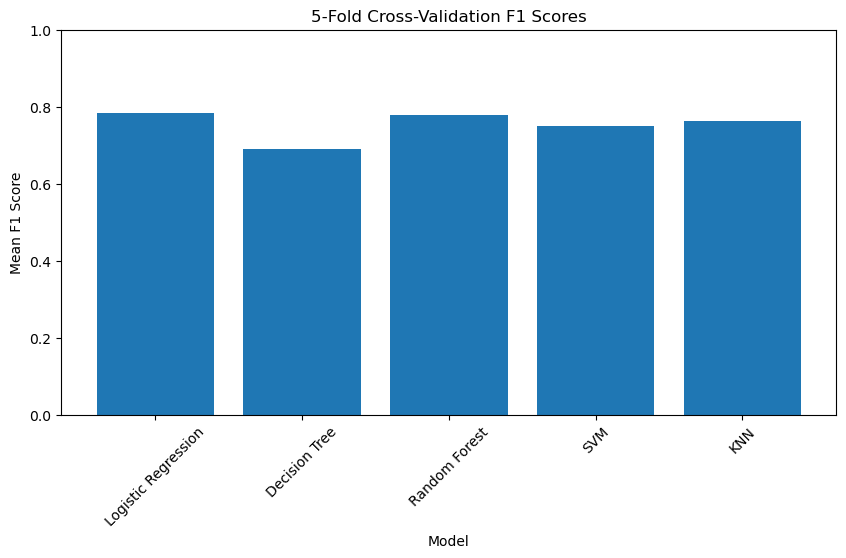

In [49]:
import matplotlib.pyplot as plt

models_cv = list(cv_results.keys())
f1_scores_cv = list(cv_results.values())

plt.figure(figsize=(10, 5))
plt.bar(models_cv, f1_scores_cv)

plt.xlabel("Model")
plt.ylabel("Mean F1 Score")
plt.title("5-Fold Cross-Validation F1 Scores")
plt.xticks(rotation=45)
plt.ylim(0, 1)

plt.show()

## Final Model Evaluation

After comparing the models using cross-validation, we evaluate the tuned Logistic Regression and Random Forest models on the unseen test dataset.

The classification report provides:
- Precision
- Recall
- F1-score
- Support

In [50]:
from sklearn.metrics import classification_report

print("Tuned Logistic Regression:")
print(classification_report(y_test, y_pred_logistic_tuned))

print("\nTuned Random Forest:")
print(classification_report(y_test, y_pred_rf_tuned))

Tuned Logistic Regression:
              precision    recall  f1-score   support

           0       0.94      0.85      0.89        20
           1       0.83      0.94      0.88        16

    accuracy                           0.89        36
   macro avg       0.89      0.89      0.89        36
weighted avg       0.90      0.89      0.89        36


Tuned Random Forest:
              precision    recall  f1-score   support

           0       1.00      0.80      0.89        20
           1       0.80      1.00      0.89        16

    accuracy                           0.89        36
   macro avg       0.90      0.90      0.89        36
weighted avg       0.91      0.89      0.89        36



## Confusion Matrix

A confusion matrix shows how many predictions were:
- True Negative (TN)
- False Positive (FP)
- False Negative (FN)
- True Positive (TP)

We will compare the tuned Logistic Regression and Random Forest models.

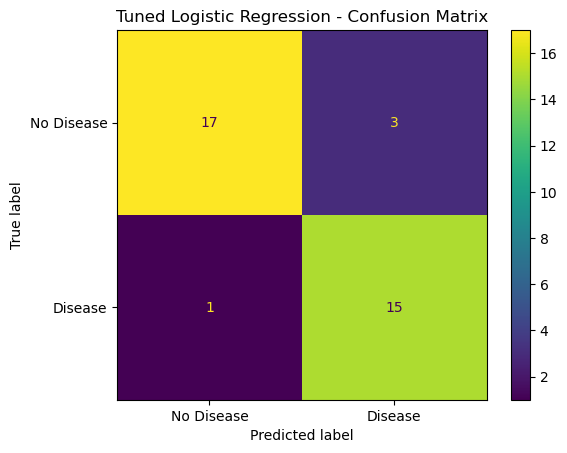

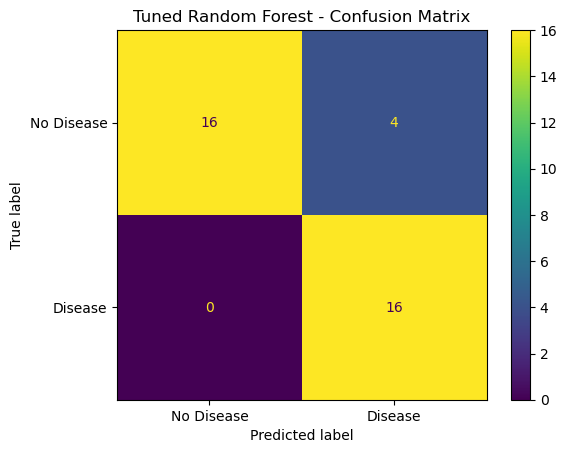

In [51]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Tuned Logistic Regression
cm_logistic = confusion_matrix(y_test, y_pred_logistic_tuned)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_logistic,
    display_labels=["No Disease", "Disease"]
)

disp.plot()
plt.title("Tuned Logistic Regression - Confusion Matrix")
plt.show()


# Tuned Random Forest
cm_rf = confusion_matrix(y_test, y_pred_rf_tuned)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=["No Disease", "Disease"]
)

disp.plot()
plt.title("Tuned Random Forest - Confusion Matrix")
plt.show()

## Final Model Comparison

We compare all trained models using accuracy, precision, recall, and F1-score.

F1-score is particularly useful here because it considers both precision and recall.

In [53]:
import pandas as pd

final_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "SVM",
        "KNN",
        "Tuned Logistic Regression",
        "Tuned Random Forest"
    ],
    "Accuracy": [
        0.888889,
        0.694444,
        0.888889,
        0.861111,
        0.861111,
        0.888889,
        0.888889
    ],
    "Precision": [
        0.800000,
        0.647059,
        0.800000,
        0.789474,
        0.789474,
        0.833333,
        0.800000
    ],
    "Recall": [
        1.000000,
        0.687500,
        1.000000,
        0.937500,
        0.937500,
        0.937500,
        1.000000
    ],
    "F1 Score": [
        0.888889,
        0.666667,
        0.888889,
        0.857143,
        0.857143,
        0.882353,
        0.888889
    ]
})

final_results

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.888889,0.800000,1.0000,0.888889
1,Decision Tree,0.694444,0.647059,0.6875,0.666667
2,Random Forest,0.888889,0.800000,1.0000,0.888889
3,SVM,0.861111,0.789474,0.9375,0.857143
4,KNN,0.861111,0.789474,0.9375,0.857143
5,Tuned Logistic Regression,0.888889,0.833333,0.9375,0.882353
6,Tuned Random Forest,0.888889,0.800000,1.0000,0.888889


## Final Model Selection

Based on the test-set evaluation and 5-fold cross-validation results, the Random Forest model provides:

- Accuracy: 88.89%
- Precision: 80.00%
- Recall: 100.00%
- F1-score: 88.89%
- 5-fold cross-validation mean F1-score: 0.7786

The tuned Random Forest model will be used as the final model for this project.

In [54]:
# Select the final model
final_model = best_rf_model

print("Final model selected: Tuned Random Forest")
print("Test Accuracy:", final_model.score(X_test_scaled, y_test))

Final model selected: Tuned Random Forest
Test Accuracy: 0.8888888888888888


## Saving the Final Model

The trained Random Forest model and StandardScaler are saved so that they can be reused later for predictions without retraining the model.

In [55]:
import joblib

# Save the final model
joblib.dump(final_model, "heart_disease_random_forest.pkl")

# Save the scaler
joblib.dump(scaler, "heart_disease_scaler.pkl")

print("Model saved successfully!")
print("Scaler saved successfully!")

Model saved successfully!
Scaler saved successfully!


## Saved Model Files

The following files will be used for future predictions:

- `heart_disease_random_forest.pkl` — trained Random Forest model
- `heart_disease_scaler.pkl` — StandardScaler used during preprocessing

In [56]:
import os

print("Model exists:", os.path.exists("heart_disease_random_forest.pkl"))
print("Scaler exists:", os.path.exists("heart_disease_scaler.pkl"))

Model exists: True
Scaler exists: True


## Feature Order for Prediction

The new patient data must follow exactly the same feature order used to train the final model.

In [57]:
print("Features required by the model:")
for i, feature in enumerate(X.columns, start=1):
    print(f"{i}. {feature}")

Features required by the model:
1. slope_of_peak_exercise_st_segment
2. resting_blood_pressure
3. num_major_vessels
4. fasting_blood_sugar_gt_120_mg_per_dl
5. serum_cholesterol_mg_per_dl
6. oldpeak_eq_st_depression
7. sex
8. age
9. max_heart_rate_achieved
10. exercise_induced_angina
11. thal_normal
12. thal_reversible_defect
13. chest_pain_type_2
14. chest_pain_type_3
15. chest_pain_type_4
16. resting_ekg_results_1
17. resting_ekg_results_2


## New Patient Prediction

The prediction function takes the required patient features, applies the same scaling used during training, and uses the final Random Forest model to make a prediction.

Prediction:
- 0 → No heart disease detected by the model
- 1 → Heart disease detected by the model

In [59]:
import numpy as np
import joblib

# Load saved model and scaler
model = joblib.load("heart_disease_random_forest.pkl")
scaler = joblib.load("heart_disease_scaler.pkl")


def predict_heart_disease(
    slope,
    resting_bp,
    major_vessels,
    fasting_sugar,
    cholesterol,
    oldpeak,
    sex,
    age,
    max_hr,
    exercise_angina,
    thal_normal,
    thal_reversible,
    chest_pain_2,
    chest_pain_3,
    chest_pain_4,
    ekg_1,
    ekg_2
):
    patient_data = np.array([[
        slope,
        resting_bp,
        major_vessels,
        fasting_sugar,
        cholesterol,
        oldpeak,
        sex,
        age,
        max_hr,
        exercise_angina,
        thal_normal,
        thal_reversible,
        chest_pain_2,
        chest_pain_3,
        chest_pain_4,
        ekg_1,
        ekg_2
    ]])

    # Scale the patient data
    patient_data_scaled = scaler.transform(patient_data)

    # Make prediction
    prediction = model.predict(patient_data_scaled)[0]

    if prediction == 0:
        return "No heart disease detected by the model"
    else:
        return "Heart disease detected by the model"

## Testing the Prediction Function

We test the model with a sample patient to make sure the complete prediction pipeline works correctly.

In [60]:
result = predict_heart_disease(
    slope=1,
    resting_bp=130,
    major_vessels=0,
    fasting_sugar=0,
    cholesterol=240,
    oldpeak=0.8,
    sex=1,
    age=55,
    max_hr=150,
    exercise_angina=0,
    thal_normal=1,
    thal_reversible=0,
    chest_pain_2=0,
    chest_pain_3=1,
    chest_pain_4=0,
    ekg_1=0,
    ekg_2=1
)

print("Prediction:", result)

Prediction: No heart disease detected by the model


C:\Users\Govardhan Goud\AppData\Roaming\Python\Python313\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


## Prediction Probability

The Random Forest model can provide the probability associated with each predicted class.

- Probability of class 0 → No heart disease
- Probability of class 1 → Heart disease

These probabilities represent the model's confidence for this dataset and should not be interpreted as a clinical diagnosis.

In [61]:
def predict_heart_disease_with_probability(
    slope,
    resting_bp,
    major_vessels,
    fasting_sugar,
    cholesterol,
    oldpeak,
    sex,
    age,
    max_hr,
    exercise_angina,
    thal_normal,
    thal_reversible,
    chest_pain_2,
    chest_pain_3,
    chest_pain_4,
    ekg_1,
    ekg_2
):
    patient_data = np.array([[
        slope,
        resting_bp,
        major_vessels,
        fasting_sugar,
        cholesterol,
        oldpeak,
        sex,
        age,
        max_hr,
        exercise_angina,
        thal_normal,
        thal_reversible,
        chest_pain_2,
        chest_pain_3,
        chest_pain_4,
        ekg_1,
        ekg_2
    ]])

    # Scale the patient data
    patient_data_scaled = scaler.transform(patient_data)

    # Prediction
    prediction = model.predict(patient_data_scaled)[0]

    # Prediction probabilities
    probabilities = model.predict_proba(patient_data_scaled)[0]

    if prediction == 0:
        result = "No heart disease detected by the model"
    else:
        result = "Heart disease detected by the model"

    print("Prediction:", result)
    print(f"No heart disease probability: {probabilities[0] * 100:.2f}%")
    print(f"Heart disease probability: {probabilities[1] * 100:.2f}%")

## Testing Prediction Probability

We test the probability prediction using the same sample patient used previously.

In [62]:
predict_heart_disease_with_probability(
    slope=1,
    resting_bp=130,
    major_vessels=0,
    fasting_sugar=0,
    cholesterol=240,
    oldpeak=0.8,
    sex=1,
    age=55,
    max_hr=150,
    exercise_angina=0,
    thal_normal=1,
    thal_reversible=0,
    chest_pain_2=0,
    chest_pain_3=1,
    chest_pain_4=0,
    ekg_1=0,
    ekg_2=1
)

Prediction: No heart disease detected by the model
No heart disease probability: 89.92%
Heart disease probability: 10.08%


C:\Users\Govardhan Goud\AppData\Roaming\Python\Python313\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


# Final Project Summary

## Dataset
- Total samples: 180
- Target variable: `heart_disease_present`
- Missing values: 0
- Features used for modeling: 17

## Preprocessing
- Removed `patient_id`
- Applied IQR capping to selected numerical features
- Applied one-hot encoding to categorical features
- Applied StandardScaler to numerical/model features
- Used stratified train-test split

## Models Evaluated
- Logistic Regression
- Decision Tree
- Random Forest
- SVM
- KNN

## Hyperparameter Tuning
- Tuned Logistic Regression using GridSearchCV
- Tuned Random Forest using GridSearchCV

## Final Model
- Model: Tuned Random Forest
- Test Accuracy: 88.89%
- Test Precision: 80.00%
- Test Recall: 100.00%
- Test F1-score: 88.89%
- 5-fold CV Mean F1-score: 0.7786

## Model Deployment Preparation
- Saved trained model as `heart_disease_random_forest.pkl`
- Saved scaler as `heart_disease_scaler.pkl`
- Created a prediction function for new patient data
- Added prediction probability output